# 04 - Counterfactual, batch-removed reconstruction

A saved model is reloaded and used to decode held-out samples of a non-reference pseudo-source as if they were the reference source. Because the technical factor is simulated, the batch-free profile is known and the correction can be scored per view and per feature. The same mechanism (swap the source conditional, replace the source block) is the one to apply on the real cell line / organoid / tumour cohort.

In [1]:
# parameters
RESULTS_DIR = "results"
DATA_DIR = "data/processed"
DATASET = "sim_c05"
VARIANT = "supervised_nocond"
FOLD = 0
REFERENCE = "cell_line"
VIEW = "transcriptomics"
N_FOLDS = 3
SEED = 0

In [2]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from mosa_disentangle import plotting
from mosa_disentangle.data import read_dataset
from mosa_disentangle.training import block_columns

sns.set_context("paper")
plt.rcParams["figure.dpi"] = 110
from mosa_disentangle.training import (build_configs, load_experiment, load_run, make_folds,
                                       split_dataset, predict_dataset, block_prototype)
from mosa_disentangle.metrics import nmse

In [3]:
run_dir = Path(RESULTS_DIR) / "runs" / DATASET / VARIANT / f"fold{FOLD}"
raw = load_experiment("config/datasets/cell_lines.yaml", f"config/variants/{VARIANT}.yaml")
raw["data"]["path"] = str(Path(DATA_DIR) / f"{DATASET}.h5mu")
raw["model"]["random_seed"] = SEED + FOLD
raw["model"]["accelerator"] = "cpu"
data_cfg, model_cfg = build_configs(raw)
dataset = read_dataset(raw["data"]["path"], data_cfg.views)
truth = read_dataset(Path(DATA_DIR) / f"{DATASET}_truth.h5mu", data_cfg.views)
val_idx = make_folds(dataset.metadata, N_FOLDS, SEED)[FOLD]
train, val = split_dataset(dataset, val_idx)
truth_val = truth.subset(val_idx)
run = load_run(run_dir, train, data_cfg, model_cfg)
print(run.model.layout.dims)

{'model_type': 4, 'tissue': 12, 'emt': 2, 'free': 48}


## Three decodings of the same held-out samples

In [4]:
ref_id = run.datamodule.batch_categories.index(REFERENCE)
pred_train = predict_dataset(run, train)
ref_rows = (train.metadata["model_type"] == REFERENCE).to_numpy()
strategies = {"as observed": {}, "source conditional -> reference": {"force_source_id": ref_id}}
if "model_type" in run.model.layout.names:
    proto = block_prototype(pred_train.latent, "model_type", ref_rows)
    strategies["conditional + source block -> reference"] = {
        "force_source_id": ref_id, "block_overrides": {"model_type": proto}}
recons = {name: predict_dataset(run, val, **kw).recon for name, kw in strategies.items()}
non_ref = (val.metadata["model_type"] != REFERENCE).to_numpy()
rows = []
for name, recon in recons.items():
    for view in val.view_names:
        seen = val.masks[view] & truth.masks[view][val_idx]
        unseen = ~val.masks[view] & truth.masks[view][val_idx]
        seen[~non_ref] = False; unseen[~non_ref] = False
        rows.append({"strategy": name, "view": view,
                     "NMSE vs truth (observed entries)": nmse(truth_val.views[view], recon[view], seen),
                     "NMSE vs truth (views missing by design)": nmse(truth_val.views[view], recon[view], unseen)})
scores = pd.DataFrame(rows)
scores.pivot(index="view", columns="strategy").round(3)

NMSE vs truth (observed entries)  \
strategy                             as observed   
view                                               
copynumber                                 1.672   
crisprcas9                                 0.591   
drugresponse                               0.635   
metabolomics                                 NaN   
methylation                                0.804   
proteomics                                 0.342   
transcriptomics                            0.754   

                                                         \
strategy        conditional + source block -> reference   
view                                                      
copynumber                                        0.962   
crisprcas9                                        0.357   
drugresponse                                      0.226   
metabolomics                                        NaN   
methylation                                       0.382   
proteomics                                        0.198   
transcriptomics                                   0.362   

                                                 \
strategy        source conditional -> reference   
view                                              
copynumber                                1.672   
crisprcas9                                0.591   
drugresponse                              0.635   
metabolomics                                NaN   
methylation                               0.804   
proteomics                                0.342   
transcriptomics                           0.754   

                NMSE vs truth (views missing by design)  \
strategy                                    as observed   
view                                                      
copynumber                                          NaN   
crisprcas9                                        0.580   
drugresponse                                      0.411   
metabolomics                                      1.028   
methylation                                         NaN   
proteomics                                        0.398   
transcriptomics                                     NaN   

                                                         \
strategy        conditional + source block -> reference   
view                                                      
copynumber                                          NaN   
crisprcas9                                        0.376   
drugresponse                                      0.256   
metabolomics                                      0.954   
methylation                                         NaN   
proteomics                                        0.224   
transcriptomics                                     NaN   

                                                 
strategy        source conditional -> reference  
view                                             
copynumber                                  NaN  
crisprcas9                                0.580  
drugresponse                              0.411  
metabolomics                              1.028  
methylation                                 NaN  
proteomics                                0.398  
transcriptomics                             NaN

## Per-feature view: does the correction undo the injected shift?

For one view, the mean difference between non-reference samples and the truth is shown per feature, before and after correction. A successful correction brings the cloud onto the diagonal.

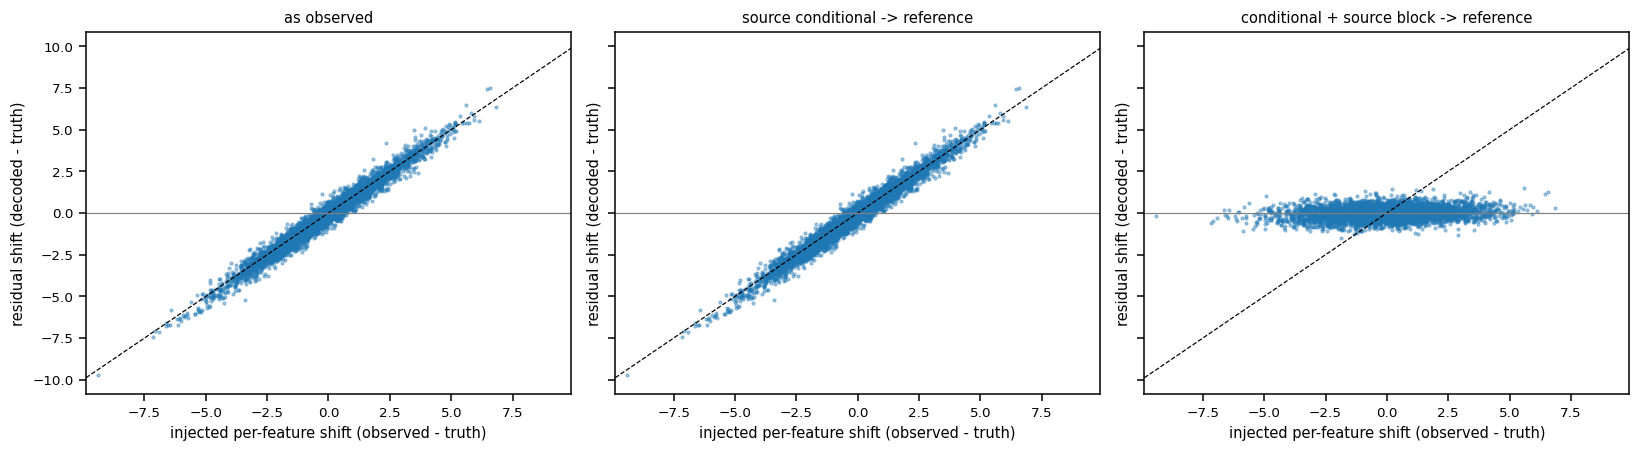

In [5]:
seen = val.masks[VIEW] & truth.masks[VIEW][val_idx]
rows_sel = non_ref & seen.any(axis=1)
def feature_bias(recon):
    diff = np.where(seen, recon - truth_val.views[VIEW], np.nan)
    return np.nanmean(diff[rows_sel], axis=0)
fig, axes = plt.subplots(1, len(recons), figsize=(5 * len(recons), 4.2), sharey=True)
observed_bias = feature_bias(np.where(seen, val.views[VIEW], np.nan))
for ax, (name, recon) in zip(np.atleast_1d(axes), recons.items()):
    bias = feature_bias(recon[VIEW])
    ax.scatter(observed_bias, bias, s=4, alpha=0.4)
    lim = np.nanmax(np.abs(observed_bias)) * 1.05
    ax.plot([-lim, lim], [-lim, lim], "k--", lw=0.8); ax.axhline(0, color="grey", lw=0.8)
    ax.set(xlabel="injected per-feature shift (observed - truth)", ylabel="residual shift (decoded - truth)",
           title=name, xlim=(-lim, lim))
plt.tight_layout()

## Latent traversal of the EMT block

Move held-out samples along the first principal direction of the EMT block and decode: the EMT marker genes should move in the expected directions while the rest of the transcriptome stays put.

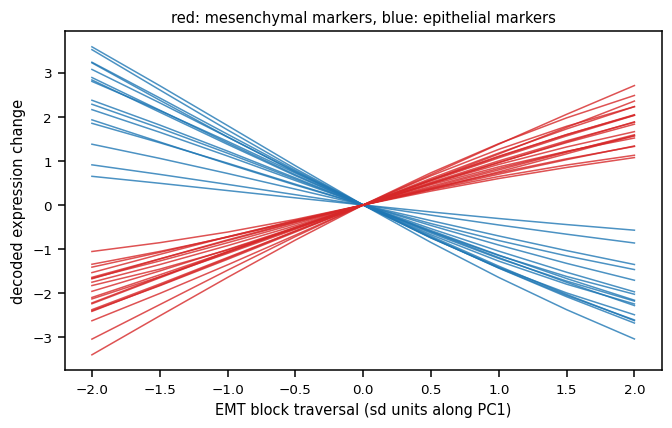

In [6]:
from mosa_disentangle.data import EPITHELIAL_GENES, MESENCHYMAL_GENES
import torch

if "emt" in run.model.layout.names:
    emt_cols = block_columns(pred_train.latent.columns, "emt")
    direction = np.linalg.svd(pred_train.latent[emt_cols].to_numpy() - pred_train.latent[emt_cols].mean().to_numpy(), full_matrices=False)[2][0]
    sd = pred_train.latent[emt_cols].to_numpy().std()
    genes = run.datamodule.feature_names[VIEW]
    markers = [g for g in EPITHELIAL_GENES + MESENCHYMAL_GENES if g in genes]
    idx = [genes.index(g) for g in markers]
    base = pred_train.latent[emt_cols].mean().to_numpy()
    steps = np.linspace(-2, 2, 9)
    traces = []
    for s in steps:
        override = {"emt": base + s * sd * direction}
        recon = predict_dataset(run, val, block_overrides=override).recon[VIEW]
        traces.append(np.nanmean(recon[:, idx], axis=0))
    traces = pd.DataFrame(traces, index=steps, columns=markers)
    traces = traces - traces.loc[0.0]
    fig, ax = plt.subplots(figsize=(7, 4))
    for g in markers:
        ax.plot(steps, traces[g], color="tab:red" if g in MESENCHYMAL_GENES else "tab:blue", lw=1, alpha=0.8)
    ax.set(xlabel="EMT block traversal (sd units along PC1)", ylabel="decoded expression change",
           title="red: mesenchymal markers, blue: epithelial markers")